# Baseline 2: Official Test Evaluation

Completed independent final ResNet-50 evaluation. This notebook preserves the recorded experiment and reviews existing evidence. Read the local record guide before running any code.


## Local record guide — Official Test

**Objective:** Completed independent final ResNet-50 evaluation.

**Architecture:** Baseline 2 uses one shared ResNet-50 backbone and separate 55-class crop and 175-class disease heads. The original method, dataset, training and analysis sections follow. The saved-evidence section at the end adds tables, existing figures and a concise discussion for this stage.

**Reading this completed record:** original execution counts, outputs and error records are preserved from `baseline2_official_test_ResNet50.ipynb`. They describe the historical execution, before these presentation/path changes. New Markdown is derived from explicitly linked artifacts; it is not a newly executed experiment.

The local setup cell locates the project root before Python imports. All original code cells are guarded by `RUN_RECORDED_WORKFLOW=False` so Run All in review mode does not train, infer, or rewrite reports. Keep that setting for review; read the saved results directly. Reproducing a historical workflow requires deliberate configuration of its controls and a fresh output directory. Original overwrite protections remain.

**Navigation:** introduction → setup → dataset → model/method → training/results → visualisation → discussion. Some optional historical cells were never executed; do not treat them as results.


## 1. Setup

The local setup cell resolves the `Baseline2` project root before importing `model_resnet50.py` and `evaluate.py`, including when opened in this evaluation subfolder.

Before running the test, check the file paths and leave `RUN_OFFICIAL_TEST = False`. Once the dataset and checkpoint checks pass, change it to `True` and run the notebook from the beginning.

In [ ]:
# Local review setup: no training, inference, or result writes.
from pathlib import Path
import os
import sys
_override = os.environ.get("B2_PROJECT_ROOT")
_start = Path(_override).expanduser().resolve() if _override else Path.cwd().resolve()
_candidates = [_start] if _override else [_start, *_start.parents]
PROJECT_DIR = next((p for p in _candidates if (p / "model.py").is_file()
                    and (p / "evaluate.py").is_file() and (p / "splits_v2").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Open the Baseline2 workspace or set B2_PROJECT_ROOT to its root.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
RUN_RECORDED_WORKFLOW = False  # Keep False to review this completed record.
print("Project:", PROJECT_DIR, "| Historical workflow disabled; saved outputs retained.")


In [1]:
if RUN_RECORDED_WORKFLOW:
    from pathlib import Path
    from datetime import datetime, timezone
    from IPython.display import display
    import hashlib, json, os, platform, random, time
    import numpy as np
    import pandas as pd
    from PIL import Image
    import matplotlib.pyplot as plt
    import torch
    import torchvision
    from torch.utils.data import DataLoader

    from model_resnet50 import load_resnet50_checkpoint
    from evaluate import (DPDDataset, read_metadata, validate_development_splits,
                          validation_transform, make_candidates, composition_scores,
                          evaluate_loader, harmonic_mean, sha256_file, image_paths)

    # Run Jupyter from the Baseline2 project folder.
    PROJECT_DIR = PROJECT_DIR.resolve()
    DATASET_ROOT = (PROJECT_DIR.parent / "DPD_Small_dataset").resolve()
    SPLIT_DIR = PROJECT_DIR / "splits_v2"
    OUTPUT_ROOT = PROJECT_DIR / "outputs"

    # Official test labels are stored in the project folder.
    OFFICIAL_SEEN_CSV = PROJECT_DIR / "DPD_Small_test_seen.csv"
    OFFICIAL_UNSEEN_CSV = PROJECT_DIR / "DPD_Small_test_unseen.csv"
    SEEN_IMAGE_ROOT = DATASET_ROOT   # flat image directory (not a 'test_seen' subfolder)
    UNSEEN_IMAGE_ROOT = DATASET_ROOT

    CHECKPOINT_PATH = OUTPUT_ROOT / "stage2_exp15_full_10e_seed42" / "final_full_data.pt"
    EXPECTED_CHECKPOINT_SHA256 = "0b4970a1fe7978a010a39e72ccaffd9826f99c09e37a3a28d2342b344194628f"

    RUN_ID = "official_resnet50_exp15_stage2_10e_once"
    OUT_DIR = OUTPUT_ROOT / RUN_ID
    RUN_OFFICIAL_TEST = False  # Check the setup before running the official test.
    VERIFY_IMAGE_CONTENT_HASHES = False  # Optional exact-duplicate image check.
    EXAMPLE_GALLERY_PER_SPLIT = 8

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    INFERENCE_BATCH_SIZE = 16
    NUM_WORKERS = 0  # Works reliably with Windows notebooks.
    USE_AUTOCAST = True
    SEED = 42

    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.benchmark = False

    print("PROJECT_DIR          :", PROJECT_DIR)
    print("DATASET_ROOT         :", DATASET_ROOT)
    print("Official seen CSV    :", OFFICIAL_SEEN_CSV)
    print("Official unseen CSV  :", OFFICIAL_UNSEEN_CSV)
    print("Stage 2 checkpoint   :", CHECKPOINT_PATH)
    print("Device               :", DEVICE)
    print("RUN_OFFICIAL_TEST    :", RUN_OFFICIAL_TEST)


PROJECT_DIR          : C:\AML\ML_Project\Baseline2
DATASET_ROOT         : C:\AML\ML_Project\DPD_Small_dataset
Official seen CSV    : C:\AML\ML_Project\Baseline2\DPD_Small_test_seen.csv
Official unseen CSV  : C:\AML\ML_Project\Baseline2\DPD_Small_test_unseen.csv
Stage 2 checkpoint   : C:\AML\ML_Project\Baseline2\outputs\stage2_exp15_full_10e_seed42\final_full_data.pt
Device               : cuda
RUN_OFFICIAL_TEST    : True


## 2. Check the evaluation functions

Composition scoring is retained from Stage 1. The recorded official run uses BICUBIC resize, while Exp09–18 development notebooks implement BILINEAR resize. This preprocessing difference limits direct protocol comparisons. The small checks below confirm that the harmonic mean, candidate-pair ranking, and image transform work as expected.

In [2]:
if RUN_RECORDED_WORKFLOW:
    def verify_metric_logic():
        c = torch.tensor([[5., 1., 0.], [0., 3., 1.]])
        d = torch.tensor([[1., 4., 0.], [2., 0., 1.]])
        tiny_candidates = torch.cartesian_prod(torch.arange(3), torch.arange(3))
        scores = composition_scores(c, d, tiny_candidates)
        assert scores.shape == (2, 9)
        assert torch.equal(tiny_candidates[scores.argmax(1)],
                           torch.tensor([[0, 1], [1, 0]]))
        assert abs(harmonic_mean(0.8, 0.2) - 0.32) < 1e-10
        assert harmonic_mean(0.0, 0.0) == 0.0
        assert len(make_candidates("all_pairs")) == 9625
        assert validation_transform().transforms[0].interpolation.name == "BICUBIC"
        print("Evaluation checks passed.")

    verify_metric_logic()


Evaluation checks passed.


## 3. Dataset and checkpoint checks

Before inference, check that the checkpoint comes from the expected Stage 2 run, the label IDs match the training setup, and there is no filename overlap between training and test data.

The *seen* test contains crop–disease pairs included in training. The *unseen* test contains new combinations of crop and disease labels that were individually observed during training. This is the compositional generalisation setting for the assignment.

In [3]:
if RUN_RECORDED_WORKFLOW:
    required_paths = [
        PROJECT_DIR / "model_resnet50.py",
        PROJECT_DIR / "evaluate.py",
        CHECKPOINT_PATH, OFFICIAL_SEEN_CSV, OFFICIAL_UNSEEN_CSV,
        SPLIT_DIR / "train_fit.csv", SPLIT_DIR / "val_seen.csv",
        SPLIT_DIR / "val_unseen.csv", SPLIT_DIR / "split_manifest.json",
    ]
    missing = [str(p) for p in required_paths if not p.is_file()]
    if missing:
        raise FileNotFoundError("missing files:\n" + "\n".join(missing))
    if not DATASET_ROOT.is_dir():
        raise FileNotFoundError(f"missing image root: {DATASET_ROOT}")

    checkpoint_sha = sha256_file(CHECKPOINT_PATH)
    if EXPECTED_CHECKPOINT_SHA256 and checkpoint_sha != EXPECTED_CHECKPOINT_SHA256:
        raise ValueError("Final checkpoint SHA256 differs from previously completed Stage 2 run. "
                         f"Expected {EXPECTED_CHECKPOINT_SHA256}, got {checkpoint_sha}. "
                         "Check which checkpoint you selected.")

    ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
    assert ckpt.get("stage") == 2 and int(ckpt.get("epoch", -1)) == 10, "Wrong Stage 2 checkpoint/epoch"
    assert int(ckpt.get("parent_best_epoch", -1)) == 12, "Expected Exp15 Stage 1 best epoch 12"
    assert int(ckpt.get("full_training_count", -1)) == 8000, "Expected full 8,000-image training"
    assert not bool(ckpt.get("former_validation_is_independent", True)), "Former validation independence flags disagree"
    cfg = ckpt["config"]
    assert cfg.get("backbone") == "resnet50", "Wrong model architecture"
    assert cfg.get("pretrained_weights") == "IMAGENET1K_V2", "Wrong original pretrained weights"
    assert int(cfg["image_size"]) == 224, "Locked evaluation input size is 224"
    assert cfg.get("candidate_mode") == "all_pairs", "Expected all 9,625 pairs"
    assert float(cfg["disease_loss_weight"]) == 1.5, "Not Exp15's Disease CE weight"
    assert int(cfg.get("additional_epochs", -1)) == 10, "Wrong Stage 2 run"
    assert cfg.get("stage2_mode") == "full", "Expected fully fine-tuned ResNet-50"
    assert int(cfg.get("stage2_seed", -1)) == 42, "Unexpected Stage 2 seed"
    PARENT_STAGE1_CHECKPOINT = OUTPUT_ROOT / "exp15_disease_weight15" / "best_development.pt"
    if PARENT_STAGE1_CHECKPOINT.is_file():
        source_sha = sha256_file(PARENT_STAGE1_CHECKPOINT)
        if source_sha != ckpt.get("parent_checkpoint_sha256"):
            raise ValueError("The original Exp15 source checkpoint differs from the Stage 2 parent hash.")
        print("PASS: Exp15 parent checkpoint SHA256 agrees with Stage 2 provenance.")
    else:
        print("Exp15 source checkpoint not found locally (hash retained in Stage 2 checkpoint).")
    checkpoint_pairs = torch.as_tensor(ckpt["candidate_pairs"], dtype=torch.long)
    assert checkpoint_pairs.shape == (9625, 2)
    assert torch.equal(checkpoint_pairs, make_candidates("all_pairs")), "Candidate pair order is different"
    assert INFERENCE_BATCH_SIZE > 0


PASS: Exp15 parent checkpoint SHA256 agrees with Stage 2 provenance.


### Check the official test splits

In [4]:
if RUN_RECORDED_WORKFLOW:
    train_frames, train_report = validate_development_splits(SPLIT_DIR)
    if train_report["sha256"] != ckpt["development_split"]["sha256"]:
        raise ValueError("Stage 2 checkpoint's training split manifest hashes do not match local splits_v2.")
    train = pd.concat(list(train_frames.values()), ignore_index=True)
    assert len(train) == 8000 and train.filename.nunique() == 8000

    seen_meta = read_metadata(OFFICIAL_SEEN_CSV)
    unseen_meta = read_metadata(OFFICIAL_UNSEEN_CSV)
    if (len(seen_meta), len(unseen_meta)) != (2000, 1448):
        raise ValueError(f"Expected official 2,000 seen / 1,448 unseen; found {len(seen_meta)}/{len(unseen_meta)}.")
    if seen_meta.filename.nunique() != len(seen_meta) or unseen_meta.filename.nunique() != len(unseen_meta):
        raise ValueError("Duplicate official test filename in CSV.")

    train_names = set(train.filename.astype(str))
    seen_names = set(seen_meta.filename.astype(str))
    unseen_names = set(unseen_meta.filename.astype(str))
    if (train_names & seen_names) or (train_names & unseen_names) or (seen_names & unseen_names):
        raise ValueError("DATA LEAKAGE: train/test or seen/unseen test filenames overlap.")

    def pairset(frame):
        return set(zip(frame.crop_id.astype(int), frame.disease_id.astype(int)))
    train_pairs = pairset(train)
    seen_pairs = pairset(seen_meta)
    unseen_pairs = pairset(unseen_meta)
    if len(train_pairs)!=323:
        raise ValueError(f"Expected 323 training-seen crop–disease compositions; found {len(train_pairs)}.")
    # Verify that a composition_id never points at two pairs and a pair never receives two IDs.
    for label,frame in [("official seen",seen_meta),("official unseen",unseen_meta)]:
        m=frame[["composition_id","crop_id","disease_id","composition_name"]].drop_duplicates()
        if m.groupby("composition_id")[["crop_id","disease_id"]].nunique().gt(1).any().any():
            raise ValueError(f"{label}: the same composition_id maps to multiple crop/disease labels.")
        if (m.groupby(["crop_id","disease_id"])["composition_id"].nunique()>1).any():
            raise ValueError(f"{label}: the same crop–disease pair is assigned multiple composition IDs.")
        if (m.groupby(["crop_id","disease_id"])["composition_name"].nunique()>1).any():
            raise ValueError(f"{label}: the same pair has inconsistent composition names.")

    if not seen_pairs.issubset(train_pairs):
        raise ValueError(f"Official seen test includes {len(seen_pairs - train_pairs)} crop–disease pair(s) not in training.")
    if unseen_pairs & train_pairs:
        raise ValueError(f"OOD INVALID: {len(unseen_pairs & train_pairs)} unseen pair(s) occur in training.")
    if seen_pairs & unseen_pairs:
        raise ValueError("Official seen and unseen test composition pairs overlap.")
    if len(unseen_pairs) != 10:
        raise ValueError(f"Expected 10 official held-out compositions; found {len(unseen_pairs)}.")
    if not set(seen_meta.crop_id).issubset(set(train.crop_id)) or not set(unseen_meta.crop_id).issubset(set(train.crop_id)):
        raise ValueError("Test contains crop concept IDs not observed in training.")
    if not set(seen_meta.disease_id).issubset(set(train.disease_id)) or not set(unseen_meta.disease_id).issubset(set(train.disease_id)):
        raise ValueError("Test contains disease concept IDs not observed in training.")

    # Verify canonical names rather than trusting filenames to determine crop/disease labels.
    crop_names = {int(k):str(v) for k,v in ckpt["class_mappings"]["crop"].items()}
    disease_names = {int(k):str(v) for k,v in ckpt["class_mappings"]["disease"].items()}
    for label, frame in [("seen", seen_meta), ("unseen", unseen_meta)]:
        for col_id, col_name, mapping in [("crop_id","crop_name",crop_names),
                                           ("disease_id","disease_name",disease_names)]:
            expected = frame[col_id].map(mapping)
            if expected.isna().any():
                raise ValueError(f"{label} uses {col_id} outside the checkpoint's label mapping.")
            mismatch = frame.loc[expected.astype(str).str.strip().str.casefold() !=
                                 frame[col_name].astype(str).str.strip().str.casefold(),
                                 [col_id, col_name]]
            if len(mismatch):
                display(mismatch.head(8))
                raise ValueError(f"{label} {col_id} ↔ {col_name} names differ from checkpoint mappings. "
                                 "Verify the original class mapping; Check the original label mapping.")

    # Seen composition IDs are validated where the checkpoint contains the ID.
    known_comp = {int(x["composition_id"]):(int(x["crop_id"]),int(x["disease_id"]))
                  for x in ckpt["composition_mapping"]}
    for name, frame in [("seen",seen_meta), ("unseen",unseen_meta)]:
        for row in frame[["composition_id","crop_id","disease_id"]].drop_duplicates().itertuples(index=False):
            if int(row.composition_id) in known_comp:
                if known_comp[int(row.composition_id)] != (int(row.crop_id),int(row.disease_id)):
                    raise ValueError(f"Composition ID mapping mismatch in official {name}: {row}")


### Check image paths and view the split sizes

In [5]:
if RUN_RECORDED_WORKFLOW:
    # A filename is an image key; do not require separate seen and unseen image folders.
    seen_paths = image_paths(seen_meta, SEEN_IMAGE_ROOT)
    unseen_paths = image_paths(unseen_meta, UNSEEN_IMAGE_ROOT)
    assert len(seen_paths)==2000 and len(unseen_paths)==1448
    assert len({str(p) for p in seen_paths}) == 2000
    assert len({str(p) for p in unseen_paths}) == 1448

    completion_file = CHECKPOINT_PATH.parent / "stage2_completion.json"
    if completion_file.is_file():
        completion = json.loads(completion_file.read_text(encoding="utf-8"))
        if completion.get("output_sha256") != checkpoint_sha:
            raise ValueError("stage2_completion.json does not match final_full_data.pt SHA256.")

    audit = pd.DataFrame([
        {"Split":"Stage 2 training", "Images":len(train), "Distinct pairs":len(train_pairs),
         "Distinct crops":train.crop_id.nunique(), "Distinct diseases":train.disease_id.nunique()},
        {"Split":"Official Seen", "Images":len(seen_meta), "Distinct pairs":len(seen_pairs),
         "Distinct crops":seen_meta.crop_id.nunique(), "Distinct diseases":seen_meta.disease_id.nunique()},
        {"Split":"Official Unseen", "Images":len(unseen_meta), "Distinct pairs":len(unseen_pairs),
         "Distinct crops":unseen_meta.crop_id.nunique(), "Distinct diseases":unseen_meta.disease_id.nunique()}
    ])
    display(audit)
    print("Checkpoint SHA256:",checkpoint_sha)
    print("Official CSV SHA256 (seen/unseen):", sha256_file(OFFICIAL_SEEN_CSV),"/",sha256_file(OFFICIAL_UNSEEN_CSV))
    print("Preflight passed: files, labels, and test splits are ready.")


,Split,Images,Distinct pairs,Distinct crops,Distinct diseases
0,Stage 2 training,8000,323,55,175
1,Official Seen,2000,323,55,175
2,Official Unseen,1448,10,9,10


Checkpoint SHA256: 0b4970a1fe7978a010a39e72ccaffd9826f99c09e37a3a28d2342b344194628f
Official CSV SHA256 (seen/unseen): 45d31d48d2260f56cc28871b44434b5243100dc90dc95652c28c377b35b45e83 / 757e3c1fdcc894004a69c21dbc00d6b818f563aa671db9ab8d315c4790c2490b
Preflight passed: files, labels, and test splits are ready.


### Optional: check for duplicate image files

The checks above use filenames. Setting `VERIFY_IMAGE_CONTENT_HASHES = True` also compares image file hashes. This can take longer and does not detect visually similar but non-identical images.

In [6]:
if RUN_RECORDED_WORKFLOW:
    def image_digest(path, block_size=1024*1024):
        h=hashlib.sha256()
        with Path(path).open("rb") as f:
            for block in iter(lambda:f.read(block_size), b""):
                h.update(block)
        return h.hexdigest()

    if VERIFY_IMAGE_CONTENT_HASHES:
        train_paths=image_paths(train,DATASET_ROOT)
        train_hashes=set(image_digest(p) for p in train_paths)
        seen_hashes=set(image_digest(p) for p in seen_paths)
        unseen_hashes=set(image_digest(p) for p in unseen_paths)
        assert not (train_hashes & seen_hashes), "Image-content leakage between train and seen test"
        assert not (train_hashes & unseen_hashes), "Image-content leakage between train and unseen test"
        assert not (seen_hashes & unseen_hashes), "Image-content overlap between test splits"
        print("No exact duplicate image files across the splits.")
    else:
        print("Optional image hash check skipped.")


Optional image hash check skipped.


## 4. Stage 2 training history

Stage 2 uses a fixed 10-epoch fine-tuning schedule on the complete training set. The curves below are **training losses**, not validation accuracy. The final checkpoint is from epoch 10 as specified before the official test.

,additional_epoch,lr_groups,train_total_loss,train_crop_loss,train_disease_loss,seconds
0,1,"[1e-06, 0.0001]",1.22730,0.26805,0.63951,64.93714
1,2,"[9.755282581475767e-07, 9.755282581475769e-05]",0.98225,0.21632,0.51062,47.07706
2,3,"[9.045084971874736e-07, 9.045084971874737e-05]",0.86708,0.18040,0.45779,44.88411
3,4,"[7.938926261462365e-07, 7.938926261462366e-05]",0.76772,0.16315,0.40304,46.57938
4,5,"[6.545084971874736e-07, 6.545084971874737e-05]",0.73745,0.14784,0.39307,46.76389
5,6,"[5e-07, 4.9999999999999996e-05]",0.69389,0.13741,0.37099,47.04123
6,7,"[3.454915028125263e-07, 3.454915028125263e-05]",0.66010,0.12708,0.35535,45.78370
7,8,"[2.0610737385376348e-07, 2.0610737385376345e-05]",0.64737,0.12096,0.35094,45.57679
8,9,"[9.549150281252633e-08, 9.549150281252631e-06]",0.62247,0.11947,0.33533,46.32912
9,10,"[2.4471741852423233e-08, 2.447174185242323e-06]",0.63726,0.11736,0.34660,46.97440


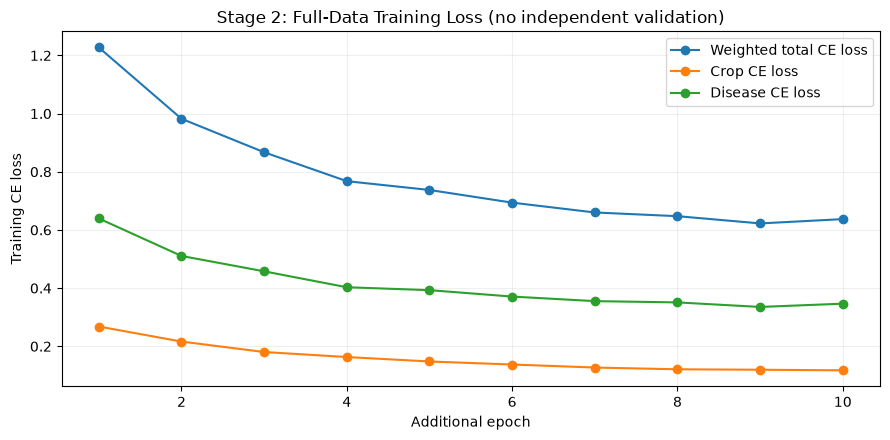

Stage 2 checkpoint used for evaluation: epoch 10
Training loss alone is not used for checkpoint selection.


In [7]:
if RUN_RECORDED_WORKFLOW:
    history_path = CHECKPOINT_PATH.parent / "full_data_history.csv"
    if history_path.is_file():
        stage2_history = pd.read_csv(history_path)
        display(stage2_history.round(5))
        expected_cols = {"additional_epoch","train_total_loss","train_crop_loss","train_disease_loss"}
        if expected_cols.issubset(stage2_history):
            fig,ax=plt.subplots(figsize=(9,4.5))
            for key,label in [
                ("train_total_loss","Weighted total CE loss"),
                ("train_crop_loss","Crop CE loss"),
                ("train_disease_loss","Disease CE loss")
            ]:
                ax.plot(stage2_history["additional_epoch"],stage2_history[key],
                        marker="o",label=label)
            ax.set(title="Stage 2: Full-Data Training Loss (no independent validation)",
                   xlabel="Additional epoch",ylabel="Training CE loss")
            ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); plt.show()
            print("Stage 2 checkpoint used for evaluation: epoch", int(ckpt["epoch"]))
            print("Training loss alone is not used for checkpoint selection.")
        else:
            print("History found but columns differ; not plotting.")
    else:
        print("Optional Stage 2 training history CSV absent; Official Test can proceed.")


## 5. Evaluate the official test sets

The completed official run uses `BICUBIC Resize(256) → CenterCrop(224)`. Exp09–18 development notebooks used BILINEAR resize; these preprocessing settings are not identical. The saved official run is preserved and is not rerun to change this protocol difference.

For a crop–disease candidate pair \((c,d)\), the score is

\[
s(c,d)=\log P(c\mid x)+\log P(d\mid x).
\]

Top-1 and Top-5 are calculated for crop, disease, and the joint pair. The inference results are saved as CSV files, so the remaining sections can be reviewed without running inference again.

**First run:** keep `RUN_OFFICIAL_TEST = False`. After the checks pass, set it to `True`. The code does not overwrite an existing test result.

In [8]:
if RUN_RECORDED_WORKFLOW:
    if RUN_OFFICIAL_TEST:
        old_run = OUTPUT_ROOT / "official_resnet50_exp15_full_10e_first_evaluation"
        if old_run.exists() and (old_run / "official_summary.json").exists():
            raise FileExistsError(
                f"An earlier Official Test output exists at {old_run}. "
                "Review the previous results instead of starting a new run.")
        if OUT_DIR.exists():
            raise FileExistsError(f"Official evaluation already exists: {OUT_DIR}\n"
                                  "Set RUN_OFFICIAL_TEST=False to read saved results. "
                                  "Keep the same evaluation protocol.")
        working_dir = OUT_DIR.with_name(OUT_DIR.name + "_INCOMPLETE")
        if working_dir.exists():
            raise FileExistsError(f"Incomplete previous run found: {working_dir}\n"
                                  "Check the partial files before trying again.")
        OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
        working_dir.mkdir(parents=False, exist_ok=False)
        started = time.perf_counter()
        try:
            model, loaded = load_resnet50_checkpoint(CHECKPOINT_PATH, DEVICE)
            if loaded["config"]["backbone"]!="resnet50":
                raise RuntimeError("Checkpoint architecture mismatch")
            transform=validation_transform()  # BICUBIC 256, center crop 224, ImageNet mean/std
            candidates = checkpoint_pairs
            loader_kwargs = dict(batch_size=INFERENCE_BATCH_SIZE, shuffle=False,
                                 num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
            loaders = {
                "seen": DataLoader(DPDDataset(seen_meta,SEEN_IMAGE_ROOT,transform),**loader_kwargs),
                "unseen": DataLoader(DPDDataset(unseen_meta,UNSEEN_IMAGE_ROOT,transform),**loader_kwargs)
            }
            prediction_tables = {}
            raw_metrics = {}
            for split,loader in loaders.items():
                print(f"Running Official {split.upper()} inference ...")
                t0=time.perf_counter()
                metrics,records = evaluate_loader(
                    model,loader,DEVICE,candidates,
                    amp=USE_AUTOCAST and DEVICE.type=="cuda", collect_predictions=True)
                if DEVICE.type=="cuda": torch.cuda.synchronize()
                elapsed=time.perf_counter()-t0
                expected_len = 2000 if split=="seen" else 1448
                if len(records)!=expected_len or int(metrics["n_images"])!=expected_len:
                    raise AssertionError(f"{split} incomplete predictions: {len(records)}/{expected_len}")
                frame=pd.DataFrame.from_records(records)
                true_frame=seen_meta if split=="seen" else unseen_meta
                if frame["filename"].astype(str).tolist()!=true_frame["filename"].astype(str).tolist():
                    raise AssertionError(f"{split} prediction order/filenames do not match official CSV.")
                raw_metrics[split] = {**metrics,"wall_seconds":elapsed,
                                      "images_per_second":len(frame)/elapsed}
                prediction_tables[split]=frame
                print(f"  {split}: n={len(frame)} | Crop top-1={metrics['crop_top1']:.2%} | "
                      f"Disease top-1={metrics['disease_top1']:.2%} | "
                      f"Composition top-1={metrics['composition_top1']:.2%}")
                frame.to_csv(working_dir / f"{split}_raw_predictions.csv",index=False)

            metadata = {
                "run_id":RUN_ID,"status":"completed","evaluated_at_utc":datetime.now(timezone.utc).isoformat(),
                "checkpoint":str(CHECKPOINT_PATH),"checkpoint_sha256":checkpoint_sha,
                "stage1_parent_best_epoch":12,"stage2_additional_final_epoch":10,
                "full_training_n":8000,"official_seen_n":2000,"official_unseen_n":1448,
                "official_csvs":{"seen":str(OFFICIAL_SEEN_CSV),"unseen":str(OFFICIAL_UNSEEN_CSV)},
                "official_csv_sha256":{"seen":sha256_file(OFFICIAL_SEEN_CSV),
                                       "unseen":sha256_file(OFFICIAL_UNSEEN_CSV)},
                "split_sha256":train_report["sha256"],
                "dataset_overlap_checks":{"file_names":True,"seen_train_pairs":True,
                    "unseen_train_pairs_disjoint":True,"canonical_class_ids":True,
                    "content_hashes":bool(VERIFY_IMAGE_CONTENT_HASHES)},
                "model":{"backbone":"resnet50","weights_origin":"IMAGENET1K_V2",
                         "architecture":"one shared backbone + crop head + disease head",
                         "crop_classes":55,"disease_classes":175,"candidate_pairs":9625,
                         "task_loss_weights":{"crop":1.0,"disease":1.5}},
                "inference":{"transform":"BICUBIC Resize(256), CenterCrop(224), ToTensor, ImageNet Normalize",
                    "batch_size":INFERENCE_BATCH_SIZE,"num_workers":NUM_WORKERS,
                    "autocast":bool(USE_AUTOCAST and DEVICE.type=="cuda"),
                    "candidate_scores":"log_softmax(crop)+log_softmax(disease)",
                    "calibration":"none"},
                "environment":{"python":platform.python_version(),"pytorch":torch.__version__,
                    "torchvision":torchvision.__version__,"device":str(DEVICE),
                    "gpu":torch.cuda.get_device_name(0) if DEVICE.type=="cuda" else None,
                    "platform":platform.platform()},
                "raw_metrics":raw_metrics,"total_wall_seconds":time.perf_counter()-started,
                "provenance_notice":"ONE-TIME independent Official Test; not used for model/epoch/seed selection"}
            (working_dir/"run_manifest.json").write_text(
                json.dumps(metadata,indent=2,default=str),encoding="utf-8")
            os.replace(working_dir,OUT_DIR)
            print("Official test completed. Results saved in:",OUT_DIR)
        except Exception as exc:
            print("Test interrupted. Partial files are in:", working_dir)
            raise
    else:
        print("Official test is disabled. Change RUN_OFFICIAL_TEST to True after preflight checks.")


Running Official SEEN inference ...
  seen: n=2000 | Crop top-1=87.55% | Disease top-1=63.65% | Composition top-1=60.80%
Running Official UNSEEN inference ...
  unseen: n=1448 | Crop top-1=64.23% | Disease top-1=6.77% | Composition top-1=2.21%
Official test completed. Results saved in: C:\AML\ML_Project\Baseline2\outputs\official_resnet50_exp15_stage2_10e_once


## 6. Load predictions and calculate metrics

This section reads the saved predictions and checks the Top-1/Top-5 values against the metrics returned during inference.

The **harmonic mean (HM)** combines seen and unseen accuracy:

\[
\mathrm{HM}=\frac{2\cdot A_{seen}\cdot A_{unseen}}{A_{seen}+A_{unseen}}.
\]

If both accuracies are zero, HM is defined as zero.

In [9]:
if RUN_RECORDED_WORKFLOW:
    RESULTS_EXIST = (OUT_DIR/"run_manifest.json").is_file()
    if not RESULTS_EXIST:
        print("No saved test results yet. Run the official evaluation to display results below.")
    else:
        manifest=json.loads((OUT_DIR/"run_manifest.json").read_text(encoding="utf-8"))
        if manifest["checkpoint_sha256"]!=checkpoint_sha:
            raise ValueError("Saved result manifest does not match the selected checkpoint.")
        pred = {
            "seen":pd.read_csv(OUT_DIR/"seen_raw_predictions.csv"),
            "unseen":pd.read_csv(OUT_DIR/"unseen_raw_predictions.csv")
        }
        for split,df in pred.items():
            official=seen_meta if split=="seen" else unseen_meta
            assert len(df)==len(official)
            assert df.filename.astype(str).tolist()==official.filename.astype(str).tolist()
            # Preserve the fixed candidate order from Stage 1.
            def parse_pairs(s): return [tuple(int(t) for t in pair) for pair in json.loads(s)]
            df["crop_top1_correct"]=(df["predicted_crop_id"]==df["crop_id"]).astype(int)
            df["disease_top1_correct"]=(df["predicted_disease_id"]==df["disease_id"]).astype(int)
            df["composition_top1_correct"]=(
                (df["predicted_pair_crop_id"]==df["crop_id"])&
                (df["predicted_pair_disease_id"]==df["disease_id"])).astype(int)
            df["crop_top5_correct"] = [
                int(int(target) in [int(x) for x in json.loads(rank)])
                for target,rank in zip(df.crop_id,df.ranked_crop_ids)]
            df["disease_top5_correct"] = [
                int(int(target) in [int(x) for x in json.loads(rank)])
                for target,rank in zip(df.disease_id,df.ranked_disease_ids)]
            df["composition_top5_correct"] = [
                int((int(c),int(d)) in parse_pairs(rank))
                for c,d,rank in zip(df.crop_id,df.disease_id,df.ranked_composition_pairs)]
            for task in ("crop","disease","composition"):
                for k in (1,5):
                    label=f"{task}_top{k}"
                    calc=df[f"{label}_correct"].mean()
                    stored=manifest["raw_metrics"][split][label]
                    assert abs(calc-stored)<1e-8,(split,label,calc,stored)
            df["true_crop_name"]=df.crop_id.map(crop_names)
            df["true_disease_name"]=df.disease_id.map(disease_names)
            df["pred_crop_name"]=df.predicted_crop_id.map(crop_names)
            df["pred_disease_name"]=df.predicted_disease_id.map(disease_names)
            df["pred_pair_crop_name"]=df.predicted_pair_crop_id.map(crop_names)
            df["pred_pair_disease_name"]=df.predicted_pair_disease_id.map(disease_names)
            df["true_pair"]=df.true_crop_name+" / "+df.true_disease_name
            df["predicted_pair"]=df.pred_pair_crop_name+" / "+df.pred_pair_disease_name
            df["split"]=split
            df["predicted_training_seen_pair"]=[
                int((int(c),int(d)) in train_pairs)
                for c,d in zip(df.predicted_pair_crop_id,df.predicted_pair_disease_id)]
        print("Top-1 and Top-5 values match the saved predictions.")
        display(pred["seen"].head(4)[["filename","true_pair","predicted_pair",
                                      "composition_top1_correct","composition_top5_correct"]])


Top-1 and Top-5 values match the saved predictions.


,filename,true_pair,predicted_pair,composition_top1_correct,composition_top5_correct
0,OD_olive_peacock_spot_3103.jpg,olive / peacock_spot,olive / peacock_spot,1,1
1,CUPD_cassava_brown_streak_disease_6335.jpg,cassava / brown_streak_disease,cassava / brown_streak_disease,1,1
2,CPDD_tomato_septoria_leaf_spot_3946.jpg,tomato / septoria_leaf_spot,tomato / septoria_leaf_spot,1,1
3,RDD1_paddy_hispa_878.jpg,paddy / hispa,paddy / leafblast,0,1


### Main result table

The main comparison uses **Top-1, Top-5 and HM** for all three tasks. Counts are also reported because unseen test accuracy can change noticeably when only a small number of predictions are correct.

In [10]:
if RUN_RECORDED_WORKFLOW:
    if RESULTS_EXIST:
        rows = []
        for task in ("crop", "disease", "composition"):
            for k in (1, 5):
                key = f"{task}_top{k}_correct"
                seen_correct = int(pred["seen"][key].sum())
                unseen_correct = int(pred["unseen"][key].sum())
                seen_acc = seen_correct / len(pred["seen"])
                unseen_acc = unseen_correct / len(pred["unseen"])
                rows.append({
                    "Task": task.title(),
                    "Top-k": k,
                    "Seen (%)": round(100 * seen_acc, 3),
                    "Unseen (%)": round(100 * unseen_acc, 3),
                    "HM (%)": round(100 * harmonic_mean(seen_acc, unseen_acc), 3),
                    "Gap (pp)": round(100 * (seen_acc - unseen_acc), 3),
                    "Seen correct": seen_correct,
                    "Unseen correct": unseen_correct,
                })

        metrics_table = pd.DataFrame(rows)
        display(metrics_table)
        metrics_table.to_csv(OUT_DIR / "official_metrics_all_tasks.csv", index=False)

        main = metrics_table[
            (metrics_table["Task"] == "Composition") &
            (metrics_table["Top-k"] == 1)
        ].iloc[0]
        print(f"Composition Top-1: Seen {main['Seen (%)']:.2f}% | "
              f"Unseen {main['Unseen (%)']:.2f}% | HM {main['HM (%)']:.2f}%")


,Task,Top-k,Seen (%),Unseen (%),HM (%),Gap (pp),Seen correct,Unseen correct
0,Crop,1,87.55,64.227,74.096,23.323,1751,930
1,Crop,5,95.90,80.870,87.746,15.030,1918,1171
2,Disease,1,63.65,6.768,12.235,56.882,1273,98
3,Disease,5,87.25,26.243,40.350,61.007,1745,380
4,Composition,1,60.80,2.210,4.265,58.590,1216,32
5,Composition,5,81.45,12.431,21.570,69.019,1629,180


Composition Top-1: Seen 60.80% | Unseen 2.21% | HM 4.26%


## 7. Visualise the results

Compare seen and unseen performance for each task, followed by the types of errors made by the two prediction heads. The visualisations are based on the saved official predictions; they are not used to select or tune the model.

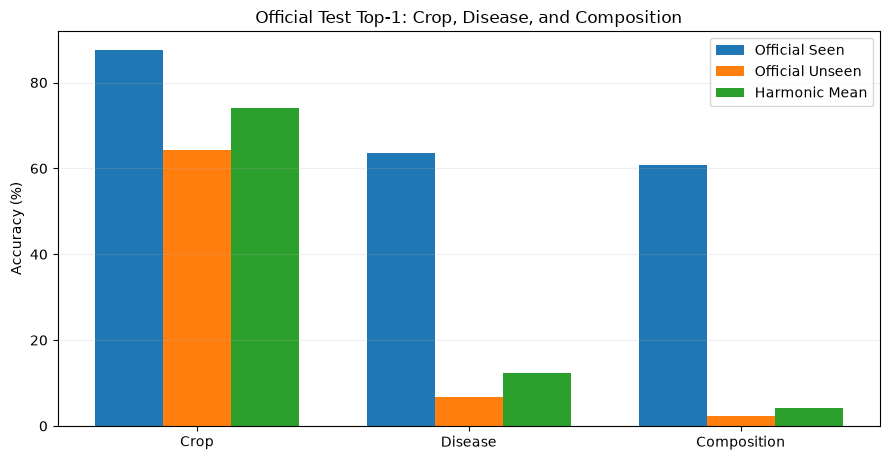

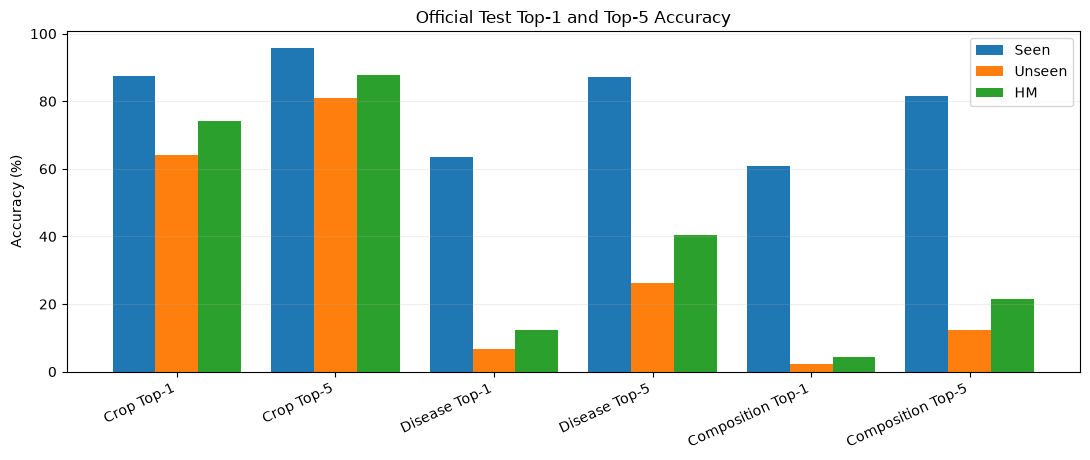

,Split,N,Predicted seen-pair rate (%),Both correct,Crop only correct,Disease only correct,Neither correct,Joint Top-1 pair correct
0,seen,2000,91.400,1216,535,57,192,1216
1,unseen,1448,67.541,32,898,66,452,32


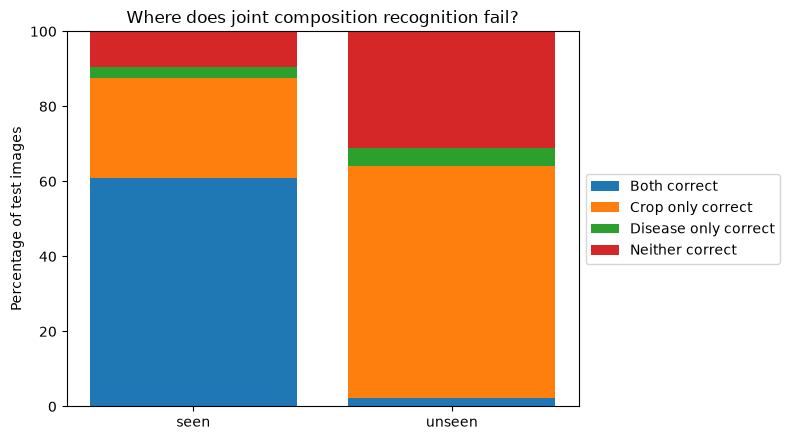

In [11]:
if RUN_RECORDED_WORKFLOW:
    if RESULTS_EXIST:
        subset=metrics_table[metrics_table["Top-k"]==1]
        x=np.arange(len(subset)); w=0.25
        fig,ax=plt.subplots(figsize=(9,4.7))
        ax.bar(x-w,subset["Seen (%)"],w,label="Official Seen")
        ax.bar(x,subset["Unseen (%)"],w,label="Official Unseen")
        ax.bar(x+w,subset["HM (%)"],w,label="Harmonic Mean")
        ax.set_xticks(x,subset.Task)
        ax.set_ylabel("Accuracy (%)")
        ax.set_title("Official Test Top-1: Crop, Disease, and Composition")
        ax.legend()
        ax.grid(axis="y",alpha=.2)
        fig.tight_layout(); fig.savefig(OUT_DIR/"official_top1_comparison.png",dpi=180)
        plt.show()

        x=np.arange(len(metrics_table)); w=.27
        fig,ax=plt.subplots(figsize=(11,4.7))
        labels=[f"{t} Top-{k}" for t,k in zip(metrics_table.Task,metrics_table["Top-k"])]
        ax.bar(x-w,metrics_table["Seen (%)"],w,label="Seen")
        ax.bar(x,metrics_table["Unseen (%)"],w,label="Unseen")
        ax.bar(x+w,metrics_table["HM (%)"],w,label="HM")
        ax.set_xticks(x,labels,rotation=25,ha="right")
        ax.set(title="Official Test Top-1 and Top-5 Accuracy",
               ylabel="Accuracy (%)")
        ax.legend(); ax.grid(axis="y",alpha=.2); fig.tight_layout()
        fig.savefig(OUT_DIR/"official_top1_top5_comparison.png",dpi=180);plt.show()

        bias_rows=[]
        for split,df in pred.items():
            counts={
                "Both correct":int(((df.crop_top1_correct==1)&(df.disease_top1_correct==1)).sum()),
                "Crop only correct":int(((df.crop_top1_correct==1)&(df.disease_top1_correct==0)).sum()),
                "Disease only correct":int(((df.crop_top1_correct==0)&(df.disease_top1_correct==1)).sum()),
                "Neither correct":int(((df.crop_top1_correct==0)&(df.disease_top1_correct==0)).sum()),
            }
            assert sum(counts.values())==len(df)
            # The product-of-marginals ranking normally agrees with the two head argmaxes,
            # but exact score ties and PyTorch topk tie-breaking can produce discrepancies.
            # Record rather than falsely treating any tie discrepancy as failed evaluation.
            counts["Joint Top-1 pair correct"]=int(df.composition_top1_correct.sum())
            if counts["Both correct"]!=counts["Joint Top-1 pair correct"]:
                print(f"NOTE: {split} has a Top-1 pair vs independent-head tie/ranking discrepancy: "
                      f"{counts['Both correct']} vs {counts['Joint Top-1 pair correct']}.")
            bias_rows.append({
                "Split":split,"N":len(df),
                "Predicted seen-pair rate (%)":round(100*df.predicted_training_seen_pair.mean(),3),
                **counts
            })
        bias_table=pd.DataFrame(bias_rows)
        display(bias_table)
        bias_table.to_csv(OUT_DIR/"error_type_and_seen_pair_bias.csv",index=False)
        fig,ax=plt.subplots(figsize=(8,4.5))
        bottom=np.zeros(2)
        for key in ["Both correct","Crop only correct","Disease only correct","Neither correct"]:
            vals=bias_table[key].to_numpy()/bias_table.N.to_numpy()*100
            ax.bar(bias_table.Split,vals,bottom=bottom,label=key)
            bottom+=vals
        ax.set(title="Where does joint composition recognition fail?",
               ylabel="Percentage of test images",ylim=(0,100))
        ax.legend(loc="center left",bbox_to_anchor=(1,0.5))
        fig.tight_layout();fig.savefig(OUT_DIR/"task_error_breakdown.png",dpi=180,bbox_inches="tight")
        plt.show()


## 8. Error analysis

Overall accuracy does not show whether the model performs poorly on particular crops, diseases, or crop–disease combinations. Here I examine class-level accuracy, rare diseases, and the more difficult compositions.

*Micro accuracy* weights each image equally. *Macro accuracy* takes the mean of the class or composition accuracies, giving each observed class or pair equal weight.

,Split,Granularity,Micro Top-1,Macro Top-1,Groups
0,seen,crop,0.8755,0.6357,55
1,seen,disease,0.6365,0.3877,175
2,seen,composition,0.6080,0.3925,323
3,unseen,crop,0.6423,0.6131,9
4,unseen,disease,0.0677,0.1371,10
5,unseen,composition,0.0221,0.0324,10



SEEN — Lowest composition accuracies


,crop_name,disease_name,n,train_pair_n,composition_correct,composition_top1_accuracy
196,paddy,hispa,12,73,0,0.0
201,paddy,yellow_stem_borer,8,21,0,0.0
36,bean,angular_leaf_spot,5,18,0,0.0
219,peanut,healthy,5,31,0,0.0
179,mango,sooty_mould,4,16,0,0.0
213,peach,scab,4,3,0,0.0
217,peach,brown_rot,4,5,0,0.0
5,apple,cedar_apple_rust,3,8,0,0.0
16,apple,venturia_inaequalis,3,8,0,0.0
31,basil,downy_mildew,3,3,0,0.0



UNSEEN — Lowest composition accuracies


,crop_name,disease_name,n,train_pair_n,composition_correct,composition_top1_accuracy
329,grape,black_rot,271,0,0,0.000000
330,mango,anthracnose,95,0,0,0.000000
324,cherry,aphis_spp,72,0,0,0.000000
327,cucumber,powdery_mildew,37,0,0,0.000000
328,cucumber,downy_mildew,32,0,0,0.000000
332,tomato,early_blight,472,0,1,0.002119
326,cotton,bacterial_blight,125,0,1,0.008000
323,pepper_bell,bacterial_spot,220,0,6,0.027273
325,corn,brown_spot,35,0,1,0.028571
331,sugarcane,rust,89,0,23,0.258427


UNSEEN — Disease recognition bottlenecks


,class_name,train_images,n,correct,accuracy
240,black_rot,36,271,0,0.000000
244,anthracnose,51,95,0,0.000000
239,aphis_spp,7,72,0,0.000000
248,early_blight,102,472,4,0.008475
241,brown_spot,261,35,1,0.028571
247,bacterial_blight,147,125,6,0.048000
245,downy_mildew,69,32,3,0.093750
246,bacterial_spot,188,220,29,0.131818
242,rust,297,89,27,0.303371
243,powdery_mildew,226,37,28,0.756757


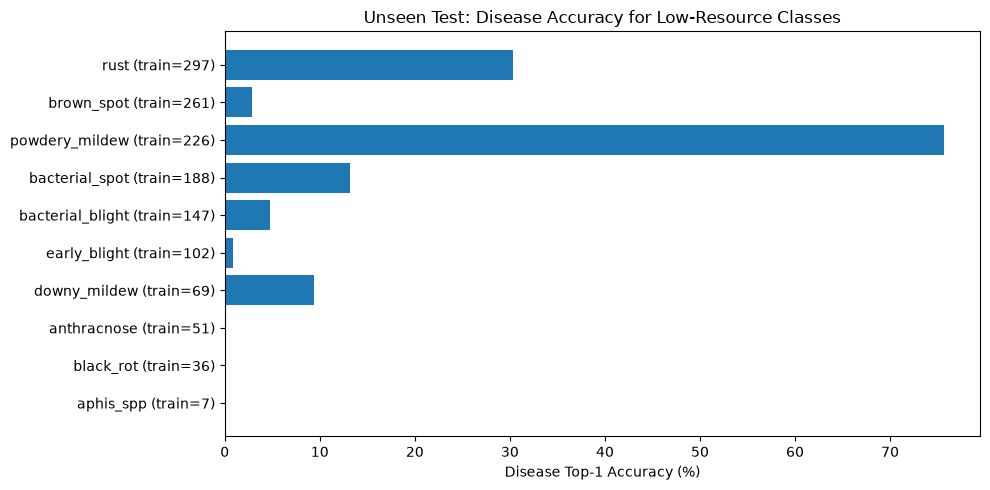

In [12]:
if RUN_RECORDED_WORKFLOW:
    if RESULTS_EXIST:
        # Frequencies from the fixed 8,000-image Stage 2 training set only.
        disease_train_counts=train.groupby("disease_id").size().to_dict()
        crop_train_counts=train.groupby("crop_id").size().to_dict()
        class_rows=[]
        pair_rows=[]
        for split,df in pred.items():
            for task in ("crop","disease"):
                id_col=task+"_id"; metric_col=task+"_top1_correct"
                group=df.groupby(id_col).agg(n=("filename","size"),correct=(metric_col,"sum")).reset_index()
                group["accuracy"]=group.correct/group.n
                group["split"]=split;group["task"]=task
                mapping=crop_names if task=="crop" else disease_names
                freqs=crop_train_counts if task=="crop" else disease_train_counts
                group["class_name"]=group[id_col].map(mapping)
                group["train_images"]=group[id_col].map(freqs).fillna(0).astype(int)
                class_rows.append(group.rename(columns={id_col:"class_id"}))
            pair=df.groupby(["crop_id","disease_id"]).agg(
                n=("filename","size"),
                composition_correct=("composition_top1_correct","sum"),
                composition_top5_correct=("composition_top5_correct","sum")
            ).reset_index()
            pair["composition_top1_accuracy"]=pair.composition_correct/pair.n
            pair["composition_top5_accuracy"]=pair.composition_top5_correct/pair.n
            pair["crop_name"]=pair.crop_id.map(crop_names)
            pair["disease_name"]=pair.disease_id.map(disease_names)
            pair["train_pair_n"]=[int(((train.crop_id==c)&(train.disease_id==d)).sum())
                                 for c,d in zip(pair.crop_id,pair.disease_id)]
            pair["split"]=split
            pair_rows.append(pair)
        class_metrics=pd.concat(class_rows,ignore_index=True)
        pair_metrics=pd.concat(pair_rows,ignore_index=True)
        class_metrics.to_csv(OUT_DIR/"official_per_class_metrics.csv",index=False)
        pair_metrics.to_csv(OUT_DIR/"official_per_composition_metrics.csv",index=False)

        macro_rows=[]
        for split,df in pred.items():
            for task in ("crop","disease"):
                table=class_metrics[(class_metrics.split==split)&(class_metrics.task==task)]
                macro_rows.append({"Split":split,"Granularity":task,
                    "Micro Top-1":df[f"{task}_top1_correct"].mean(),
                    "Macro Top-1":table.accuracy.mean(),"Groups":len(table)})
            table=pair_metrics[pair_metrics.split==split]
            macro_rows.append({"Split":split,"Granularity":"composition",
                "Micro Top-1":df.composition_top1_correct.mean(),
                "Macro Top-1":table.composition_top1_accuracy.mean(),"Groups":len(table)})
        macro_table=pd.DataFrame(macro_rows)
        display(macro_table.round(4))
        macro_table.to_csv(OUT_DIR/"official_micro_macro_comparison.csv",index=False)

        for split in ("seen","unseen"):
            subset=pair_metrics[pair_metrics.split==split].sort_values(
                ["composition_top1_accuracy","n"],ascending=[True,False])
            print(f"\n{split.upper()} — Lowest composition accuracies")
            display(subset.head(12)[["crop_name","disease_name","n","train_pair_n",
                                      "composition_correct","composition_top1_accuracy"]])

        unseen_diseases=class_metrics[(class_metrics.split=="unseen")&
                                      (class_metrics.task=="disease")].sort_values(
            ["accuracy","n"],ascending=[True,False])
        print("UNSEEN — Disease recognition bottlenecks")
        display(unseen_diseases.head(15)[["class_name","train_images","n","correct","accuracy"]])

        rare=unseen_diseases.sort_values(["train_images","n"]).head(16)
        fig,ax=plt.subplots(figsize=(10,5))
        ax.barh(rare.class_name.astype(str)+" (train="+rare.train_images.astype(str)+")",
                rare.accuracy.to_numpy()*100)
        ax.set(title="Unseen Test: Disease Accuracy for Low-Resource Classes",
               xlabel="Disease Top-1 Accuracy (%)")
        fig.tight_layout()
        fig.savefig(OUT_DIR/"unseen_low_resource_disease_accuracy.png",dpi=180,bbox_inches="tight")
        plt.show()


### Confusion matrices

The full confusion matrices are saved as CSV files. For the seen composition plot, only the most common true pairs are shown so the figure remains readable; predictions outside the displayed labels are grouped into `OTHER PREDICTIONS`.

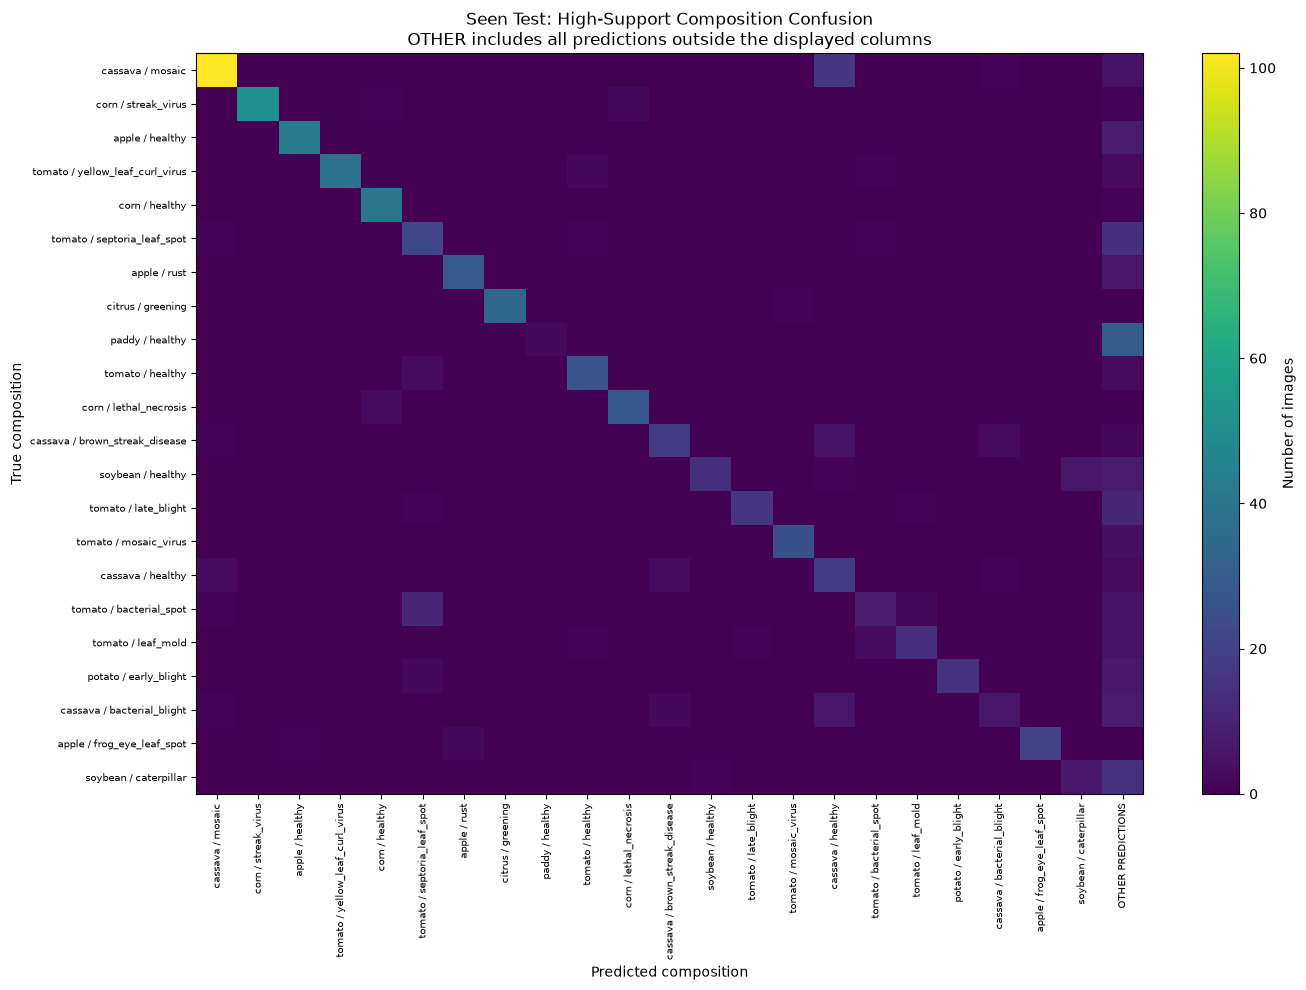

Saved crop/disease/full-composition confusion CSVs for BOTH official splits.


In [13]:
if RUN_RECORDED_WORKFLOW:
    def confusion_artifacts(df, split, out_dir, max_visible_pairs=22):
        for task in ("crop","disease"):
            a=df[f"{task}_id"]
            b=df[f"predicted_{task}_id"]
            matrix=pd.crosstab(a,b,rownames=[f"true_{task}_id"],
                               colnames=[f"predicted_{task}_id"])
            matrix.to_csv(out_dir/f"{split}_{task}_confusion_FULL.csv")

        matrix=pd.crosstab(df["true_pair"],df["predicted_pair"],
                           rownames=["True crop / disease"],
                           colnames=["Pred crop / disease"])
        matrix.to_csv(out_dir/f"{split}_composition_confusion_FULL.csv")
        assert int(matrix.to_numpy().sum())==len(df)
        if split=="seen":
            names=df.true_pair.value_counts().head(max_visible_pairs).index.tolist()
            label_set=set(names)
            view=df.loc[df.true_pair.isin(label_set)].copy()
            view["predicted_group"]=view.predicted_pair.where(
                view.predicted_pair.isin(label_set),"OTHER PREDICTIONS")
            columns=names+["OTHER PREDICTIONS"]
            small=pd.crosstab(view.true_pair,view.predicted_group).reindex(
                index=names,columns=columns,fill_value=0)
            small.to_csv(out_dir/"seen_composition_confusion_TOP_SUPPORT_with_OTHER.csv")
            fig,ax=plt.subplots(figsize=(14,10))
            im=ax.imshow(small.values,aspect="auto")
            ax.set_xticks(np.arange(len(columns)),labels=columns,rotation=90,fontsize=7)
            ax.set_yticks(np.arange(len(names)),labels=names,fontsize=7)
            ax.set(title="Seen Test: High-Support Composition Confusion\n"
                         "OTHER includes all predictions outside the displayed columns",
                   xlabel="Predicted composition",ylabel="True composition")
            fig.colorbar(im,ax=ax,label="Number of images")
            fig.tight_layout()
            fig.savefig(out_dir/"seen_composition_confusion_TOP_SUPPORT.png",
                        dpi=180,bbox_inches="tight")
            plt.show()

    if RESULTS_EXIST:
        for split,df in pred.items():
            confusion_artifacts(df,split,OUT_DIR)
        print("Saved crop/disease/full-composition confusion CSVs for BOTH official splits.")


### Examples of incorrect predictions

A few incorrect examples help explain what the model confuses. These are for discussing model limitations, **not** for changing the model after checking the official test.

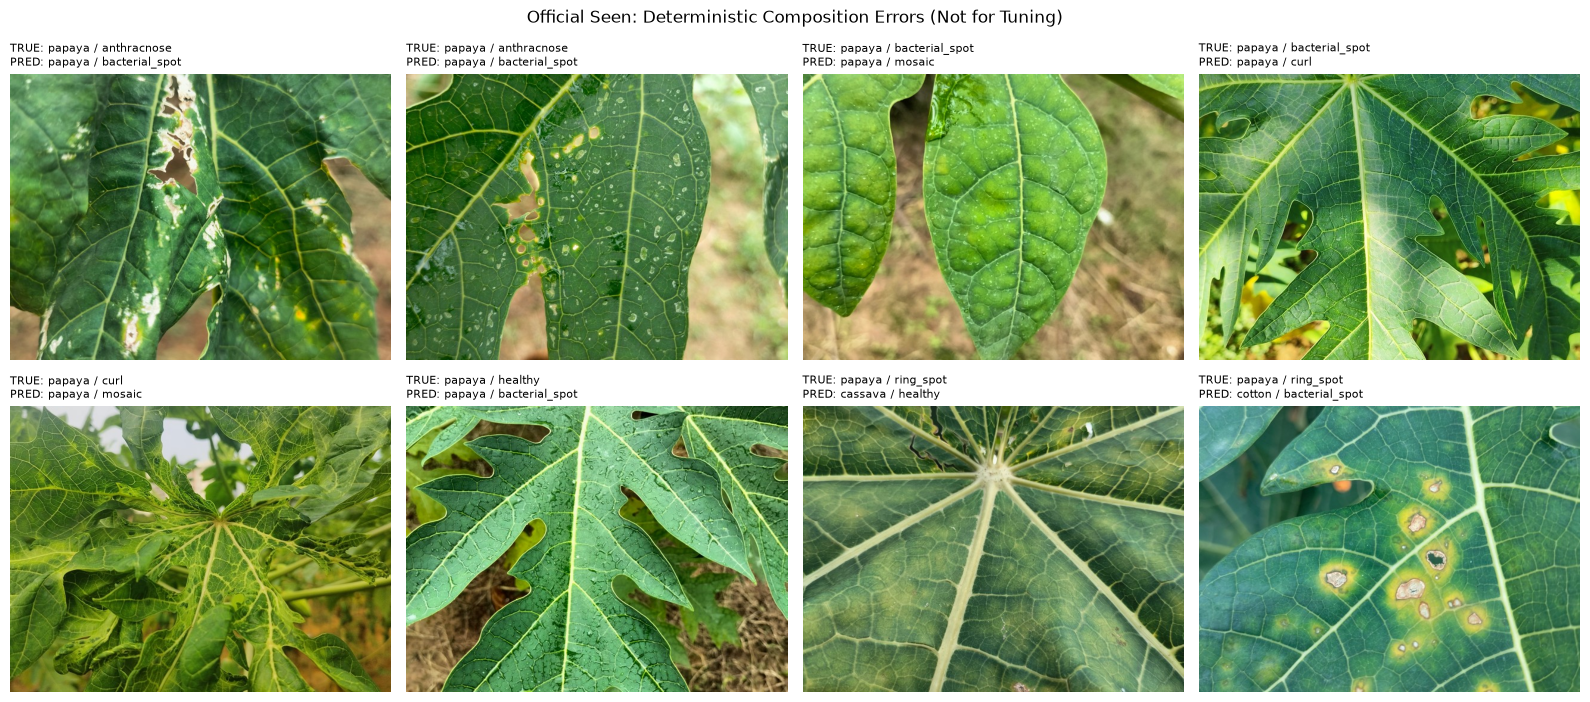

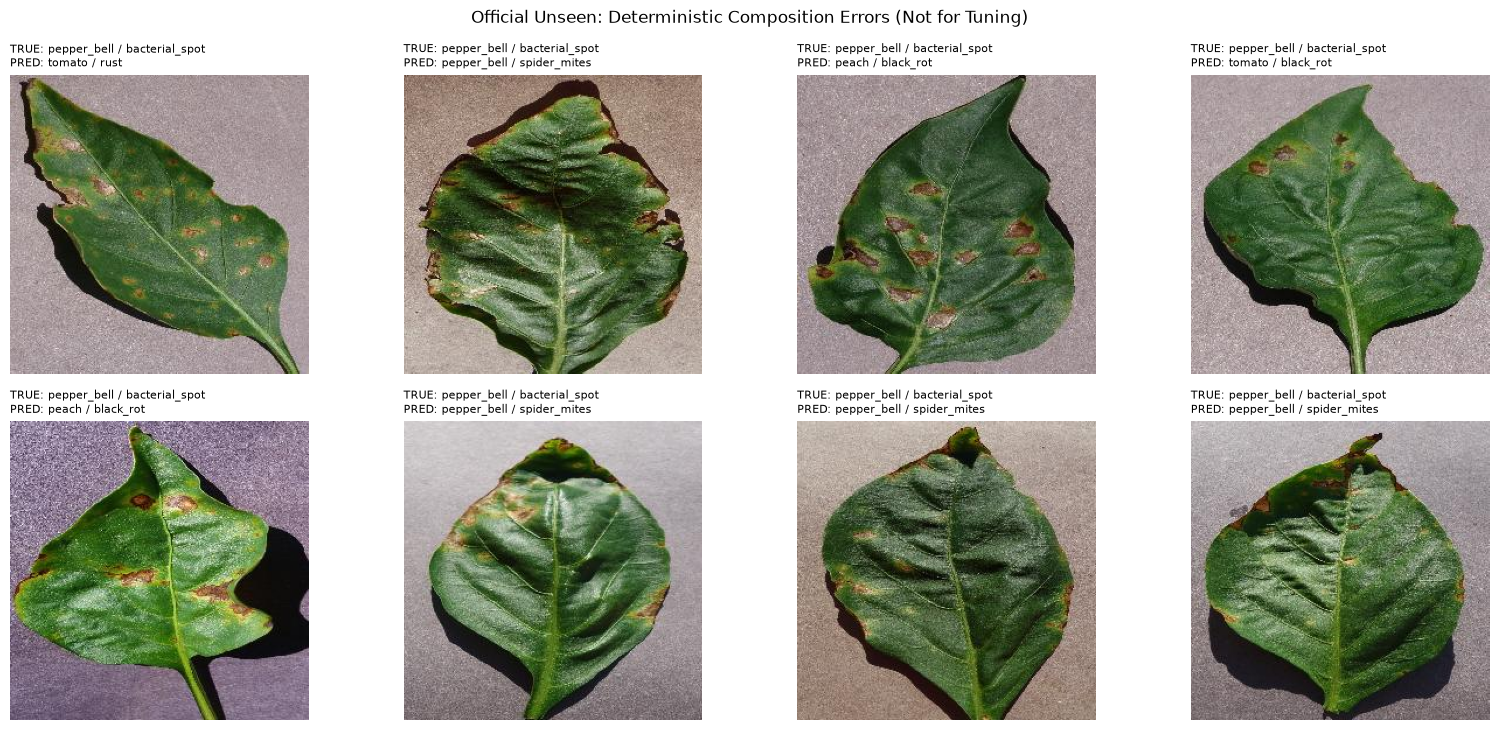

In [14]:
if RUN_RECORDED_WORKFLOW:
    def save_error_gallery(df,root,split,out_dir,max_examples=8):
        # Deterministic: first wrong examples in alphabetical filename order.
        errors=df[df.composition_top1_correct==0].sort_values("filename").head(max_examples)
        if errors.empty:
            print(split,": no composition errors to display")
            return
        n=len(errors);cols=4;rows=(n+cols-1)//cols
        fig,axes=plt.subplots(rows,cols,figsize=(4*cols,3.7*rows))
        axes=np.asarray(axes).reshape(-1)
        for ax,rec in zip(axes,errors.to_dict("records")):
            filename=str(rec["filename"])
            path=(Path(root)/filename).resolve()
            with Image.open(path) as im:
                ax.imshow(im.convert("RGB"))
            ax.axis("off")
            ax.set_title(f"TRUE: {rec['true_pair']}\nPRED: {rec['predicted_pair']}",
                         fontsize=8,loc="left",wrap=True)
        for ax in axes[n:]:ax.axis("off")
        fig.suptitle(f"Official {split.title()}: Deterministic Composition Errors (Not for Tuning)",
                     fontsize=12)
        fig.tight_layout()
        fig.savefig(out_dir/f"{split}_composition_error_gallery.png",dpi=160,
                    bbox_inches="tight")
        plt.show()

    if RESULTS_EXIST:
        save_error_gallery(pred["seen"],SEEN_IMAGE_ROOT,"seen",OUT_DIR,EXAMPLE_GALLERY_PER_SPLIT)
        save_error_gallery(pred["unseen"],UNSEEN_IMAGE_ROOT,"unseen",OUT_DIR,EXAMPLE_GALLERY_PER_SPLIT)


## 9. Discussion

After running the notebook, use the tables and figures above to discuss:

- How crop, disease and composition accuracy differ.
- The gap between seen and unseen compositions and the resulting harmonic mean.
- Whether errors are concentrated in particular disease classes or low-sample compositions.
- Whether the model tends to predict crop–disease pairs that appeared during training.

The official test measures the final model's performance. It does **not** establish that Stage 2 improved over Stage 1, because the development and official test splits are different.

For comparisons with Baseline 1 or another approach, use the same test split, label mapping, candidate-pair rule and metric definitions. Differences in evaluation image size or preprocessing should be reported.

## Saved evidence and interpretation

This section was assembled from existing local artifacts on 23 November 2026. It does not rerun any model. Historical cell outputs below/above remain unchanged.

### Dataset and method

Independent official seen/unseen sets contain 2,000/1,448 images. Evaluation uses BICUBIC Resize(256), CenterCrop(224), ImageNet normalisation and all 9,625 crop–disease pairs, without calibration. The saved manifest identifies the final checkpoint by SHA-256.

### Independent official results

| Task | Top-k | Seen (%) | Unseen (%) | HM (%) | Gap (pp) | Seen correct | Unseen correct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Crop | 1 | 87.55 | 64.227 | 74.096 | 23.323 | 1751 | 930 |
| Crop | 5 | 95.9 | 80.87 | 87.746 | 15.03 | 1918 | 1171 |
| Disease | 1 | 63.65 | 6.768 | 12.235 | 56.882 | 1273 | 98 |
| Disease | 5 | 87.25 | 26.243 | 40.35 | 61.007 | 1745 | 380 |
| Composition | 1 | 60.8 | 2.21 | 4.265 | 58.59 | 1216 | 32 |
| Composition | 5 | 81.45 | 12.431 | 21.57 | 69.019 | 1629 | 180 |

Percentages and counts are copied from the saved CSV, including its rounding. This is the final Stage 2 model; Stage 1 development figures are a different evaluation protocol.

### Visualisation and artifact sources


**official_resnet50_exp15_stage2_10e_once**

[run_manifest.json](../../../outputs/official_resnet50_exp15_stage2_10e_once/run_manifest.json), [official_metrics_all_tasks.csv](../../../outputs/official_resnet50_exp15_stage2_10e_once/official_metrics_all_tasks.csv)


![official_resnet50_exp15_stage2_10e_once — official_top1_top5_comparison.png](../../../outputs/official_resnet50_exp15_stage2_10e_once/official_top1_top5_comparison.png)


![official_resnet50_exp15_stage2_10e_once — task_error_breakdown.png](../../../outputs/official_resnet50_exp15_stage2_10e_once/task_error_breakdown.png)


![official_resnet50_exp15_stage2_10e_once — unseen_low_resource_disease_accuracy.png](../../../outputs/official_resnet50_exp15_stage2_10e_once/unseen_low_resource_disease_accuracy.png)


![official_resnet50_exp15_stage2_10e_once — unseen_composition_error_gallery.png](../../../outputs/official_resnet50_exp15_stage2_10e_once/unseen_composition_error_gallery.png)

### Discussion and limitations

The final Stage 2 Exp15 checkpoint gives composition Top-1 60.80% seen (1,216/2,000) and 2.21% unseen (32/1,448), HM 4.265%. Disease Top-1 falls from 63.65% seen to 6.768% unseen, compared with crop Top-1 87.55% and 64.227%. This suggests disease recognition and unseen composition transfer remain major limitations. Use the saved class supports, confusion tables and error galleries to qualify this aggregate result. This evaluation is independent of model selection; do not tune configurations, seeds, epochs or calibration from it. Image-content overlap hashing was disabled in the recorded manifest, so only the documented filename and label checks are established.

**Preprocessing limitation:** The saved official manifest and current evaluator specify BICUBIC resizing; the recorded Exp09–18 development functions specify BILINEAR. The earlier wording claiming identical Stage 1 preprocessing was inaccurate. This review changes the description only, with no official rerun or result edits.
